# CSP101 Final Project
Analysis of YouTube Trending Videos Across Countries

## 1. Imports and configuration

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Paths
BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"
OUTPUT_DIR = BASE_DIR / "project_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)  # create output folder if missing

# Country code
COUNTRY_NAMES = {
    "BR": "Brazil", "CA": "Canada", "DE": "Germany", "IN": "India",
    "JP": "Japan", "RU": "Russia", "US": "United States",
}

# YouTube category_id -> name
CATEGORY_NAMES = {
    1: "Film & Animation", 2: "Autos & Vehicles", 10: "Music",
    15: "Pets & Animals", 17: "Sports", 19: "Travel & Events", 20: "Gaming",
    22: "People & Blogs", 23: "Comedy", 24: "Entertainment",
    25: "News & Politics", 26: "Howto & Style", 27: "Education",
    28: "Science & Technology", 29: "Nonprofits & Activism",
    30: "Movies", 43: "Shows",
}

# Columns every CSV must contain
REQUIRED_COLUMNS = [
    "video_id", "trending_date", "title", "channel_title", "views",
    "likes", "dislikes", "publish_time", "category_id", "tags",
    "comments", "channel_id", "description",
]

# Columns to convert to numbers
NUMERIC_COLUMNS = ["views", "likes", "dislikes", "comments", "category_id"]

## 2. Loading helpers

In [2]:
def read_csv_robust(path, issues):
    # Try UTF-8, then Latin-1; fall back to the Python parser on malformed rows.
    for enc in ("utf-8", "latin-1"):
        try:
            return pd.read_csv(path, low_memory=False, encoding=enc)
        except UnicodeDecodeError:
            continue  # try next encoding
        except pd.errors.ParserError:
            # Skip bad rows and record the issue
            frame = pd.read_csv(path, engine="python",
                                on_bad_lines="skip", encoding=enc)
            issues.append({"file": path.name,
                           "status": "Loaded after skipping malformed rows",
                           "details": "CSV parser reported malformed row(s)."})
            return frame


def load_data():
    frames, issues = [], []

    # Look in data/ first, then next to the notebook
    search_dir = DATA_DIR if DATA_DIR.exists() else BASE_DIR
    csv_files = sorted(search_dir.glob("*_Trending.csv"))
    if not csv_files:
        csv_files = sorted(BASE_DIR.glob("*_Trending.csv"))
    if not csv_files:
        raise FileNotFoundError(
            "No data found. Put the *_Trending.csv files in a folder named 'data'."
        )

    for path in csv_files:
        try:
            frame = read_csv_robust(path, issues)
            frame["country_code"] = path.name.split("_")[0].upper()  # e.g. "US"
            frame["source_file"] = path.name
            frames.append(frame)
        except Exception as exc:
            # Unreadable file: log it and move on
            issues.append({"file": path.name, "status": "Skipped",
                           "details": f"{type(exc).__name__}: {exc}"})

    if not frames:
        raise RuntimeError("No country datasets could be loaded.")

    data = pd.concat(frames, ignore_index=True, sort=False)
    return data, pd.DataFrame(issues, columns=["file", "status", "details"])

## 3. Cleaning function

In [4]:
def clean_data(raw_data):
    df = raw_data.copy()
    original_rows = len(df)

    # Tidy column names and check required columns exist
    df.columns = df.columns.astype(str).str.strip()
    missing = [c for c in REQUIRED_COLUMNS if c not in df.columns]
    if missing:
        raise ValueError("Missing expected columns: " + ", ".join(missing))

    # Trim text columns; empty strings become missing
    for col in ["video_id", "title", "channel_title", "channel_id"]:
        df[col] = df[col].astype("string").str.strip().replace("", pd.NA)

    # Convert to numbers / dates (bad values become NaN / NaT)
    for col in NUMERIC_COLUMNS:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df["trending_date"] = pd.to_datetime(
        df["trending_date"].astype("string").str.strip(),
        format="%y.%d.%m", errors="coerce")  # format is YY.DD.MM
    df["publish_time"] = pd.to_datetime(df["publish_time"], errors="coerce", utc=True)

    # Drop rows missing key fields
    n = len(df)
    df = df.dropna(subset=["video_id", "views", "likes", "comments"])
    removed_missing = n - len(df)

    # Drop rows with negative counts (NaN dislikes are allowed)
    n = len(df)
    count_cols = ["views", "likes", "dislikes", "comments"]
    df = df[~(df[count_cols] < 0).any(axis=1)]
    removed_negative = n - len(df)

    # Drop duplicate country + video + trending day
    n = len(df)
    df = df.drop_duplicates(subset=["country_code", "video_id", "trending_date"], keep="first")
    removed_dupes = n - len(df)

    # Readable names, falling back to the raw code/ID
    df["country_name"] = df["country_code"].map(COUNTRY_NAMES).fillna(df["country_code"])
    df["category_name"] = df["category_id"].map(CATEGORY_NAMES).fillna(
        df["category_id"].apply(lambda x: f"ID {int(x)}" if pd.notna(x) else "Unknown"))

    # Engagement = (likes + comments) / views, in percent (NaN if no views)
    df["engagement_rate_pct"] = (
        (df["likes"] + df["comments"]) / df["views"] * 100
    ).where(df["views"] > 0)

    # Log-scaled counts for plotting (+1 avoids log(0))
    for col in ["views", "likes", "comments"]:
        df[f"log_{col}"] = np.log10(df[col] + 1)

    log = pd.DataFrame([
        {"step": "Rows loaded before cleaning", "rows": original_rows,
         "explanation": "All records read from the country CSV files that loaded."},
        {"step": "Rows removed for missing key metrics/ID", "rows": removed_missing,
         "explanation": "Missing video_id, views, likes or comments."},
        {"step": "Rows removed for negative count values", "rows": removed_negative,
         "explanation": "Negative views, likes, dislikes or comments are invalid."},
        {"step": "Duplicate records removed", "rows": removed_dupes,
         "explanation": "Duplicate country + video_id + trending_date."},
        {"step": "Rows retained after cleaning", "rows": len(df),
         "explanation": "Records available for descriptive analysis."},
    ])
    return df, log

## 4. Load and clean the data

In [5]:
# Load and clean
raw_data, load_issues = load_data()
df, cleaning_log = clean_data(raw_data)

# Save outputs
for name, frame in {
    "cleaning_log": cleaning_log,
    "load_issues": load_issues,
    "cleaned_youtube_trending_data": df,
}.items():
    frame.to_csv(OUTPUT_DIR / f"{name}.csv", index=False)

# Summary
print(f"Countries loaded: {sorted(df['country_code'].unique())}")
display(cleaning_log)
if not load_issues.empty:
    print("WARNING: some files had problems")
    display(load_issues)

Countries loaded: ['BR', 'CA', 'DE', 'IN', 'JP', 'RU', 'US']


,step,rows,explanation
0,Rows loaded before cleaning,113599,All records read from the country CSV files th...
1,Rows removed for missing key metrics/ID,0,"Missing video_id, views, likes or comments."
2,Rows removed for negative count values,0,"Negative views, likes, dislikes or comments ar..."
3,Duplicate records removed,0,Duplicate country + video_id + trending_date.
4,Rows retained after cleaning,113599,Records available for descriptive analysis.


## 5. Latest snapshot per video
Views are cumulative, so each video appears once per country (its latest trending record) for category/country comparisons and correlations. Channel counts still use all records.

In [6]:
# Keep each video's most recent trending record per country
latest = (df.sort_values("trending_date")
            .groupby(["country_code", "video_id"])
            .tail(1))
print(f"All records: {len(df):,} | Unique country-video pairs: {len(latest):,}")

All records: 113,599 | Unique country-video pairs: 113,599


## 6. Summary tables

In [7]:
def summarise(frame, by):
    # Per-group stats, sorted by median views (highest first)
    return (frame.groupby(by, dropna=False)
        .agg(records=("video_id", "size"),
             unique_videos=("video_id", "nunique"),
             mean_views=("views", "mean"),
             median_views=("views", "median"),
             mean_likes=("likes", "mean"),
             mean_comments=("comments", "mean"),
             mean_engagement_rate_pct=("engagement_rate_pct", "mean"))
        .reset_index()
        .sort_values("median_views", ascending=False))

# Summaries use each video's latest record only
country_summary = summarise(latest, ["country_code", "country_name"])
category_summary = summarise(latest, ["category_id", "category_name"])
category_ranked = category_summary[category_summary["records"] >= 20]  # skip tiny categories

# Channel summary uses all records (how often a channel trends)
channel_summary = (df.groupby(["channel_id", "channel_title"], dropna=False)
    .agg(trending_records=("video_id", "size"),
         unique_videos=("video_id", "nunique"),
         countries_present=("country_code", "nunique"),
         mean_views=("views", "mean"))
    .reset_index()
    .sort_values(["trending_records", "unique_videos"], ascending=False))

# Save outputs
for name, frame in {
    "country_summary": country_summary,
    "category_summary_all": category_summary,
    "category_summary_ranked": category_ranked,
    "channel_summary": channel_summary,
}.items():
    frame.to_csv(OUTPUT_DIR / f"{name}.csv", index=False)

display(country_summary)
display(category_ranked.head(10))
display(channel_summary.head(10))

,country_code,country_name,records,unique_videos,mean_views,median_views,mean_likes,mean_comments,mean_engagement_rate_pct
5,RU,Russia,16200,16200,1.206855e+06,353332.0,39239.628148,1617.859753,4.520243
1,CA,Canada,16200,16200,2.137314e+06,296480.0,48822.350988,1685.441543,11.861008
4,JP,Japan,16200,16200,1.114590e+06,258400.0,30007.891667,994.265370,5.415425
6,US,United States,16400,16400,1.742673e+06,227514.5,42664.497500,1438.095122,12.017356
3,IN,India,16199,16199,1.370102e+06,180600.0,40210.943021,1337.583122,3.201072
0,BR,Brazil,16200,16200,1.227387e+06,176221.0,30183.704198,1216.594938,5.380418
2,DE,Germany,16200,16200,1.039973e+06,176105.5,29571.640864,885.846173,3.871567


,category_id,category_name,records,unique_videos,mean_views,median_views,mean_likes,mean_comments,mean_engagement_rate_pct
3,15,Pets & Animals,230,171,4.887140e+06,1244661.0,104335.730435,1013.934783,3.801575
5,19,Travel & Events,98,65,2.897038e+06,1130868.0,152438.387755,1579.346939,5.782132
8,23,Comedy,500,429,1.896671e+06,941652.0,71908.466000,1392.816000,4.628505
11,26,Howto & Style,216,157,3.700597e+06,662474.0,77808.356481,1109.162037,4.383130
1,2,Autos & Vehicles,492,391,1.545911e+06,440123.0,43207.851626,897.371951,3.327917
4,17,Sports,1352,1219,1.499798e+06,394197.0,41367.661243,601.144970,3.149388
12,27,Education,329,285,1.665543e+06,324890.0,64536.118541,1313.841945,5.594622
6,20,Gaming,48612,41568,1.414049e+06,317622.5,38325.099934,1669.582366,4.032844
13,28,Science & Technology,533,364,1.432404e+06,260084.0,44175.921201,1133.864916,5.058531
10,25,News & Politics,925,829,4.981954e+05,224230.0,16644.766486,1061.576216,4.444731


,channel_id,channel_title,trending_records,unique_videos,countries_present,mean_views
3159,UCLkAepWjdylmXSltofFvsYQ,BANGTANTV,3500,500,7,1.515529e+06
7269,UCooVYzDxdwTtGYAkcPmOgOw,Brawl Stars,2400,400,6,1.075085e+07
982,UC68nKdrLbLL0Vj7ilVkLmmg,Saregama Telugu,2000,500,4,7.382997e+05
6600,UCjmJDM5pRKbUlVIzDYYWb6g,Warner Bros.,2000,500,4,9.642641e+05
7101,UCngRsuvI1zxHR9vwNZvpTAw,My Singing Monsters,2000,500,4,3.142095e+05
7107,UCnjDfkZQJpaB91w3gbgbhOA,Aura Serenity,2000,500,4,9.886717e+04
4667,UCWOA1ZGywLbqmigxE4Qlvuw,Netflix,1501,501,4,1.061140e+06
5585,UCbulh9WdLtEXiooRcYK7SWw,Metallica,1500,500,3,6.458671e+05
1081,UC6pGDc4bFGD1_36IKv3FnYg,Crunchyroll,1096,501,3,1.232257e+05
3057,UCKy1dAqELo0zrOtPkf0eTMw,IGN,1003,503,5,9.699025e+04


## 7. Correlations

In [8]:
# Spearman on raw counts; Pearson on log-scaled counts
metric_corr = latest[["views", "likes", "comments"]].corr(method="spearman")
log_corr = latest[["log_views", "log_likes", "log_comments"]].corr(method="pearson")

# Save outputs
for name, corr in {
    "spearman_correlations": metric_corr,
    "log_pearson_correlations": log_corr,
}.items():
    corr.reset_index(names="metric").to_csv(OUTPUT_DIR / f"{name}.csv", index=False)

display(metric_corr.round(4))
display(log_corr.round(4))

,views,likes,comments
views,1.0000,0.8908,0.7991
likes,0.8908,1.0000,0.8505
comments,0.7991,0.8505,1.0000


,log_views,log_likes,log_comments
log_views,1.0000,0.8552,0.8020
log_likes,0.8552,1.0000,0.8266
log_comments,0.8020,0.8266,1.0000


## 8. Figures

### Figure 1: Top categories by median views

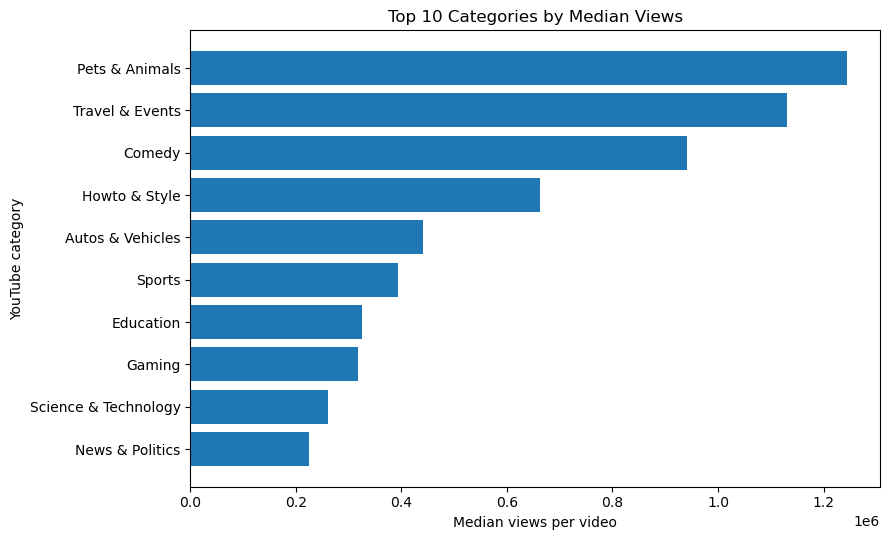

In [9]:
# Top 10 categories by median views (sorted ascending so the largest bar is on top)
cat = category_ranked.head(10).sort_values("median_views")

plt.figure(figsize=(9, 5.5))
plt.barh(cat["category_name"], cat["median_views"])
plt.xlabel("Median views per video")
plt.ylabel("YouTube category")
plt.title("Top 10 Categories by Median Views")
plt.tight_layout()

# Save, then show
plt.savefig(OUTPUT_DIR / "figure1_category_median_views.png", dpi=300, bbox_inches="tight")
plt.show()

### Figure 2: Views vs likes

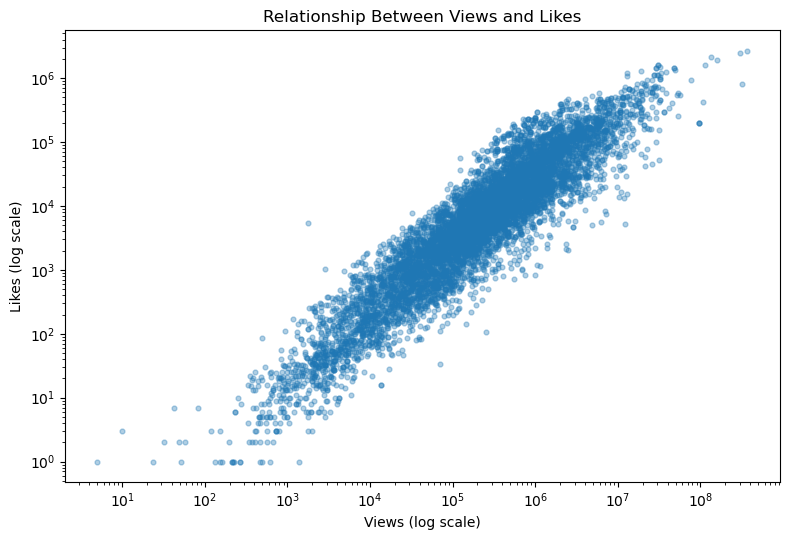

In [10]:
# Keep rows that can be shown on log axes, then sample for readability
sample = latest[(latest["views"] > 0) & (latest["likes"] > 0)]
sample = sample.sample(min(len(sample), 8000), random_state=42)

plt.figure(figsize=(8, 5.5))
plt.scatter(sample["views"], sample["likes"], alpha=0.35, s=12)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Views (log scale)")
plt.ylabel("Likes (log scale)")
plt.title("Relationship Between Views and Likes")
plt.tight_layout()

# Save, then show
plt.savefig(OUTPUT_DIR / "figure2_views_vs_likes.png", dpi=300, bbox_inches="tight")
plt.show()

### Figure 3: Median views by country

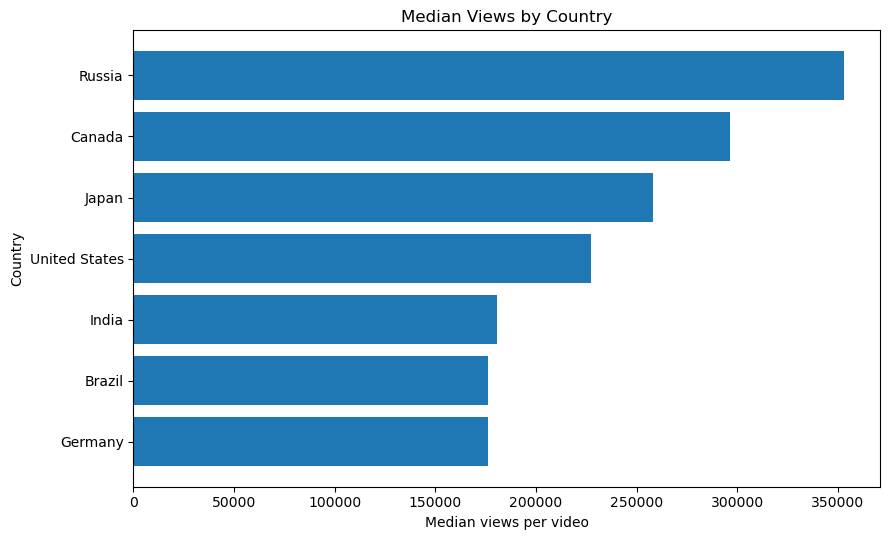

In [11]:
# Countries sorted ascending so the largest bar is on top
cp = country_summary.sort_values("median_views")

plt.figure(figsize=(9, 5.5))
plt.barh(cp["country_name"], cp["median_views"])
plt.xlabel("Median views per video")
plt.ylabel("Country")
plt.title("Median Views by Country")
plt.tight_layout()

# Save, then show
plt.savefig(OUTPUT_DIR / "figure3_country_median_views.png", dpi=300, bbox_inches="tight")
plt.show()

### Figure 4: Top channels by trending records

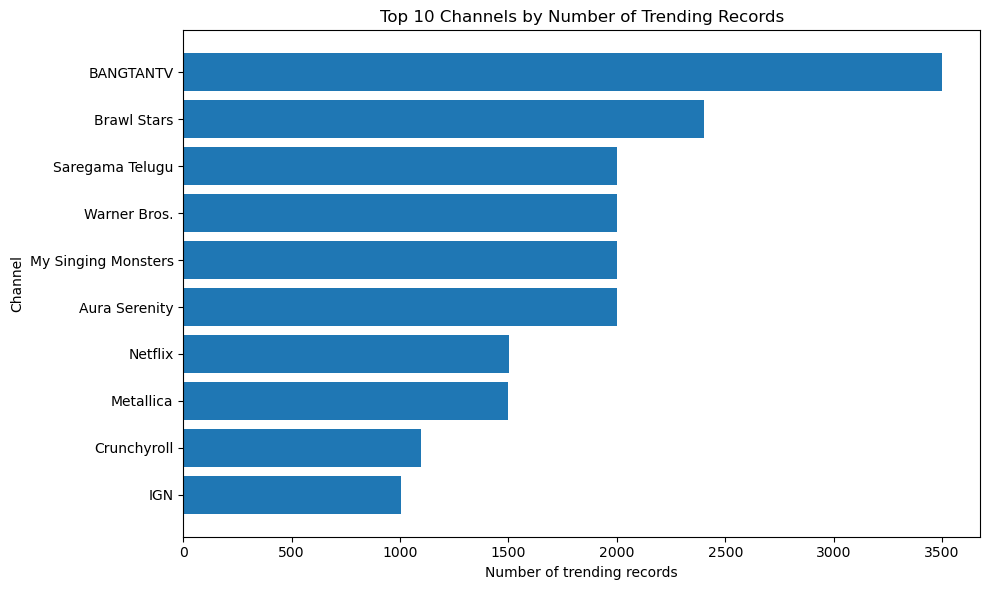

In [12]:
# Top 10 channels by trending records (ascending so the largest bar is on top)
ch = channel_summary.head(10).sort_values("trending_records")

plt.figure(figsize=(10, 6))
plt.barh(ch["channel_title"].astype(str), ch["trending_records"])  # astype(str) handles missing titles
plt.xlabel("Number of trending records")
plt.ylabel("Channel")
plt.title("Top 10 Channels by Number of Trending Records")
plt.tight_layout()

# Save, then show
plt.savefig(OUTPUT_DIR / "figure4_top_channels.png", dpi=300, bbox_inches="tight")
plt.show()

## 9. Plain-language summary

In [13]:
# Headline results (top row of each already-sorted summary)
bc = category_ranked.iloc[0] if not category_ranked.empty else None
bco = country_summary.iloc[0]
tc = channel_summary.iloc[0]
top_eng = country_summary.sort_values("mean_engagement_rate_pct", ascending=False).iloc[0]

lines = [
    "CSP101 YouTube Trending Videos Analysis - Generated Summary",
    "=" * 62,
    f"Cleaned records analysed: {len(df):,}",
    f"Unique country-video pairs (latest snapshot): {len(latest):,}",
    f"Countries represented: {df['country_code'].nunique()}",
    f"Date range: {df['trending_date'].min()} to {df['trending_date'].max()}",
    "",
    "RQ1: Which categories have the highest median views?",
    (f"{bc['category_name']} (median views = {bc['median_views']:,.0f}; "
     f"videos = {int(bc['records']):,})." if bc is not None
     else "No category had at least 20 records."),
    "",
    "RQ2: How are views associated with likes and comments?",
    f"Spearman, views-likes: {metric_corr.loc['views', 'likes']:.4f}",
    f"Spearman, views-comments: {metric_corr.loc['views', 'comments']:.4f}",
    f"Pearson, log views-log likes: {log_corr.loc['log_views', 'log_likes']:.4f}",
    f"Pearson, log views-log comments: {log_corr.loc['log_views', 'log_comments']:.4f}",
    "Correlation does not establish causation.",
    "",
    "RQ3: How do views and engagement differ across countries?",
    f"Highest median views: {bco['country_name']} ({bco['median_views']:,.0f}).",
    f"Highest mean engagement rate: {top_eng['country_name']} ({top_eng['mean_engagement_rate_pct']:.2f}%).",
    "",
    "RQ4: Which channels appear most often?",
    f"{tc['channel_title']} ({int(tc['trending_records']):,} trending records).",
]

# Note any load problems as a limitation
if not load_issues.empty:
    lines += ["", "Data limitation:",
              "Some files had loading problems (see load_issues.csv). "
              "Findings cover only the files that loaded."]

# Save and print
summary = "\n".join(lines)
(OUTPUT_DIR / "analysis_summary.txt").write_text(summary, encoding="utf-8")
print(summary)

CSP101 YouTube Trending Videos Analysis - Generated Summary
Cleaned records analysed: 113,599
Unique country-video pairs (latest snapshot): 113,599
Countries represented: 7
Date range: 2026-02-26 00:00:00 to 2026-02-26 00:00:00

RQ1: Which categories have the highest median views?
Pets & Animals (median views = 1,244,661; videos = 230).

RQ2: How are views associated with likes and comments?
Spearman, views-likes: 0.8908
Spearman, views-comments: 0.7991
Pearson, log views-log likes: 0.8552
Pearson, log views-log comments: 0.8020
Correlation does not establish causation.

RQ3: How do views and engagement differ across countries?
Highest median views: Russia (353,332).
Highest mean engagement rate: United States (12.02%).

RQ4: Which channels appear most often?
BANGTANTV (3,500 trending records).
